In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
sc.__version__

'1.11.5'

### Differentiaton of iNeurons

In [2]:
### landing pad NGN2 differentiation
adata = sc.read('../differentiations/adatas/iNeurons_counts.h5ad')
adata

AnnData object with n_obs × n_vars = 2712 × 36601
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Sample_colors'

In [3]:
adata.obs.Sample.unique()

['iNeurons_NGN2_diff']
Categories (1, object): ['iNeurons_NGN2_diff']

In [4]:
### remove genes
sc.pp.filter_genes(adata, min_cells=2)
adata.X.shape

(2712, 24868)

In [5]:
adata.layers["raw"] = adata.X.copy() # preserve counts 
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()
adata.raw = adata # keep normalised log1p as raw

In [6]:
sc.pp.highly_variable_genes(
    adata,
    subset=True,
    layer="raw",
    flavor="seurat_v3",
    n_top_genes=2000,
    span=0.3,
    min_disp=0.5,
    min_mean=0.0125,
    max_mean=3,
    batch_key='Sample'
)
print(f"adata.X shape: {adata.X.shape}")
print(f"adata.raw.X shape: {adata.raw.X.shape}")

adata.X shape: (2712, 2000)
adata.raw.X shape: (2712, 24868)


In [7]:
# regress out unwanted covariates
sc.pp.regress_out(
    adata,
    keys=["n_genes_by_counts", "pct_counts_ribo", "pct_counts_mt"],
)

# scale genes to unit variance / zero mean
sc.pp.scale(adata, max_value=10)

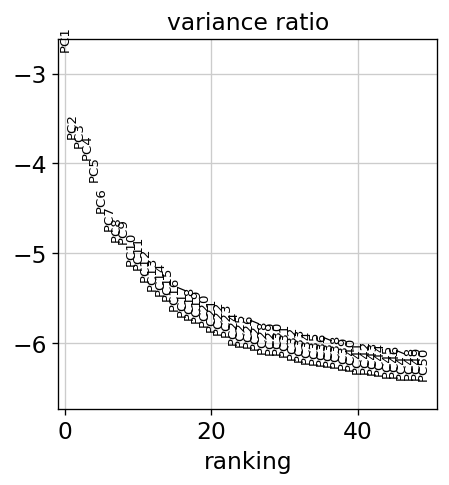

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

In [9]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

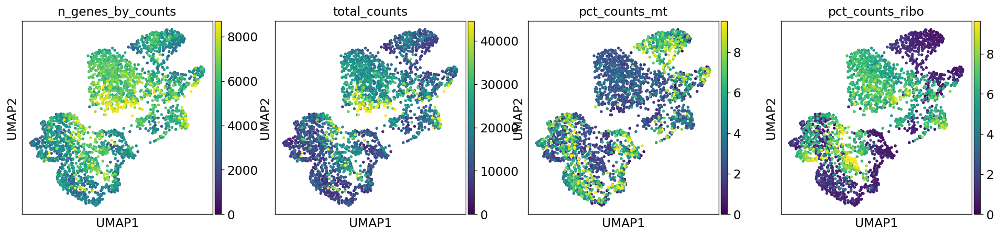

In [10]:
sc.pl.umap(adata, color=["n_genes_by_counts", "total_counts", "pct_counts_mt","pct_counts_ribo"], vmin=0, vmax='p99')

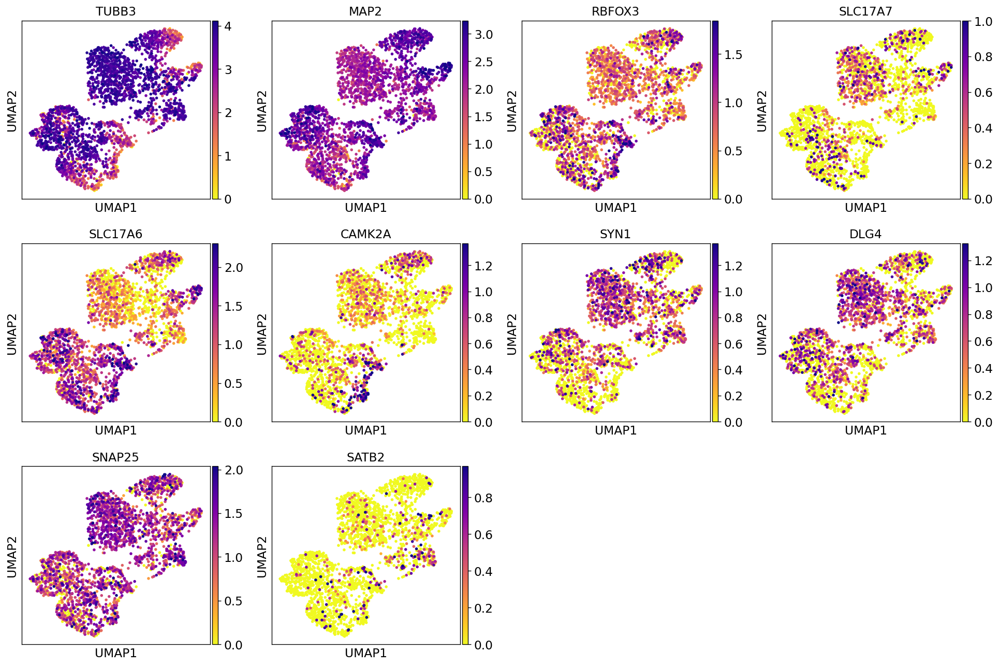

In [12]:
markers = [
    "TUBB3", "MAP2", "RBFOX3",      # neuronal
    "SLC17A7", "SLC17A6", "CAMK2A", # excitatory
    "SYN1", "DLG4", "SNAP25",       # synaptic maturation
    "SATB2",        # forebrain/cortical-ish
]
sc.pl.umap(adata, color=markers, vmin=0, vmax='p99', cmap='plasma_r')

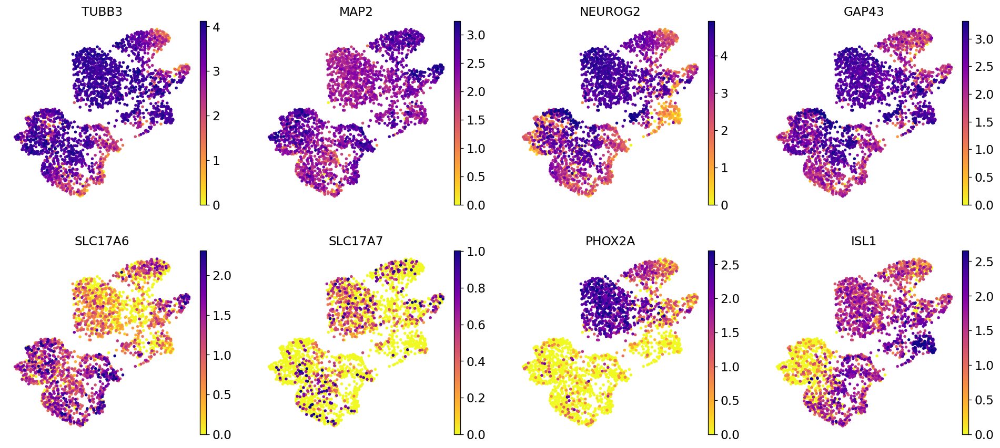

In [13]:
markers = ["TUBB3", "MAP2","NEUROG2",#"RBFOX3",
           "GAP43","SLC17A6", "SLC17A7","PHOX2A","ISL1"]
sc.pl.umap(adata, color=markers, vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,
           save='_iNeurons_NGN2_differentiation.pdf'
          )

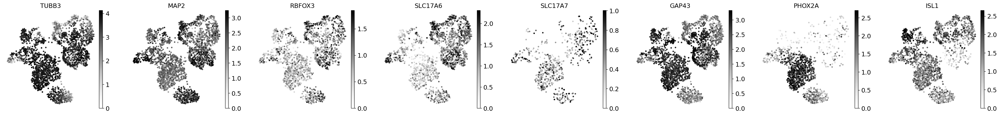

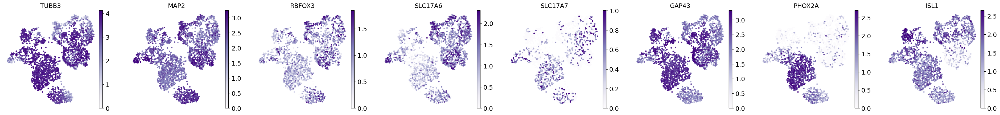

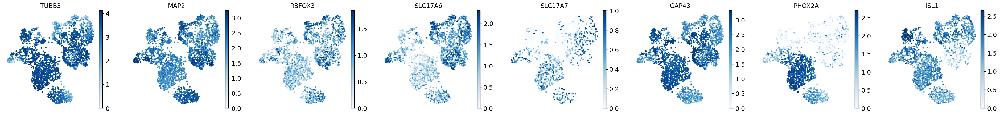

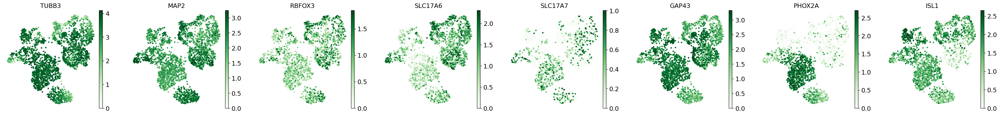

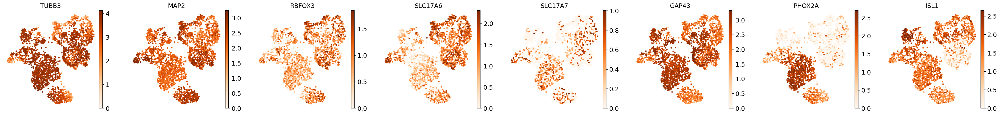

...

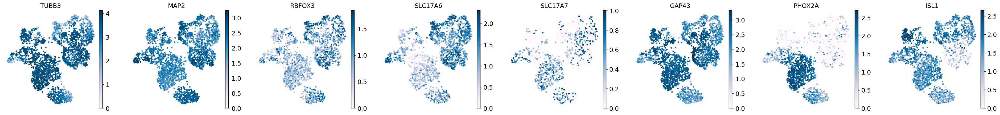

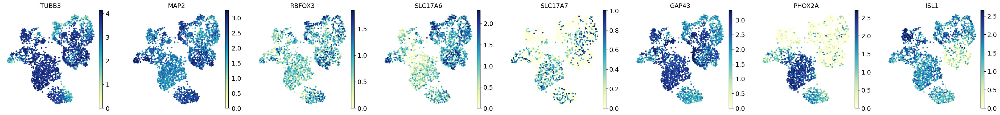

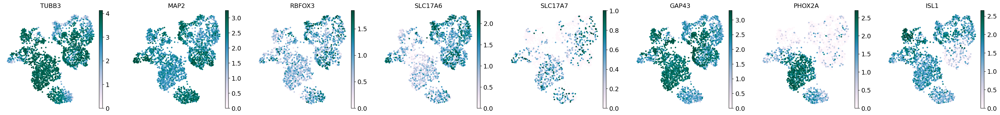

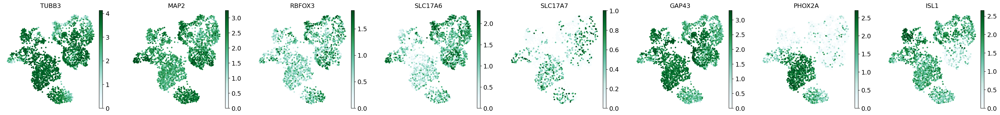

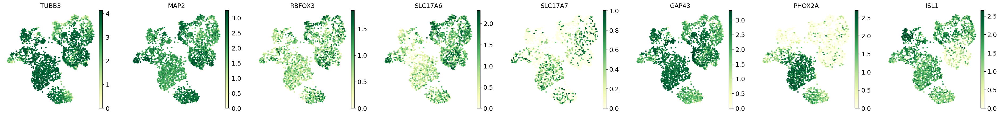

In [22]:
markers = ["TUBB3", "MAP2", "RBFOX3","SLC17A6", "SLC17A7","GAP43","PHOX2A","ISL1"]
for c in ['Greys', 'Purples', 'Blues', 'Greens', 'Oranges', 'Reds',
                      'YlOrBr', 'YlOrRd', 'OrRd', 'PuRd', 'RdPu', 'BuPu',
                      'GnBu', 'PuBu', 'YlGnBu', 'PuBuGn', 'BuGn', 'YlGn']:
      sc.pl.umap(adata, color=markers, vmin=0, vmax='p99', cmap=c,frameon=False,ncols=8)

### Differentiation of iAstrocytes

In [14]:
### landing pad NGN2 differentiation
adata = sc.read('../differentiations/adatas/iAstrocytes_counts.h5ad')
adata

AnnData object with n_obs × n_vars = 1798 × 36601
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Sample_colors'

In [15]:
### remove genes
sc.pp.filter_genes(adata, min_cells=1)
adata.X.shape

(1798, 28097)

In [16]:
adata.layers["raw"] = adata.X.copy() # preserve counts 
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()
adata.raw = adata # keep normalised log1p as raw

In [17]:
sc.pp.highly_variable_genes(
    adata,
    subset=True,
    layer="raw",
    flavor="seurat_v3",
    n_top_genes=2000,
    span=0.3,
    min_disp=0.5,
    min_mean=0.0125,
    max_mean=3,
    batch_key='Sample'
)
print(f"adata.X shape: {adata.X.shape}")
print(f"adata.raw.X shape: {adata.raw.X.shape}")

adata.X shape: (1798, 2000)
adata.raw.X shape: (1798, 28097)


In [18]:
# regress out unwanted covariates
sc.pp.regress_out(adata,keys=["n_genes_by_counts", "pct_counts_ribo", "pct_counts_mt"],)

# scale genes to unit variance / zero mean
sc.pp.scale(adata, max_value=10)

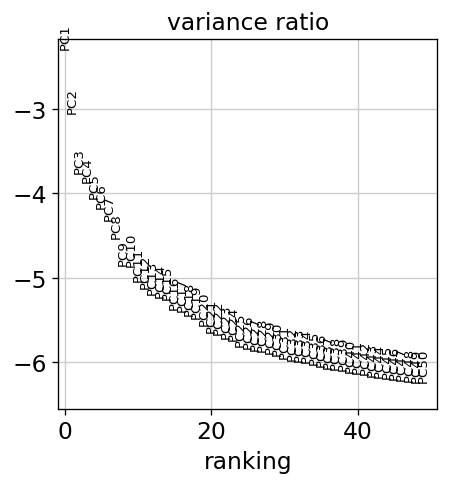

In [19]:
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

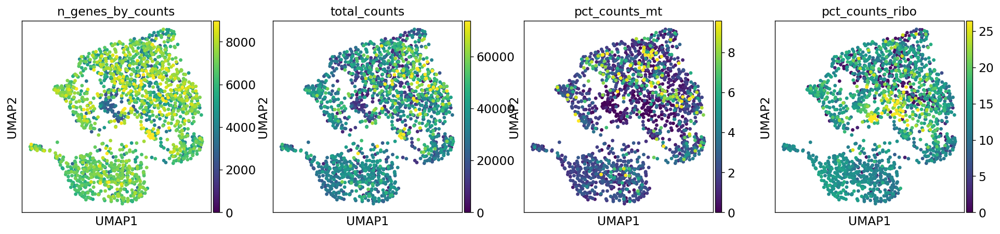

In [20]:
sc.pl.umap(adata, color=["n_genes_by_counts", "total_counts", "pct_counts_mt","pct_counts_ribo"], vmin=0, vmax='p99')

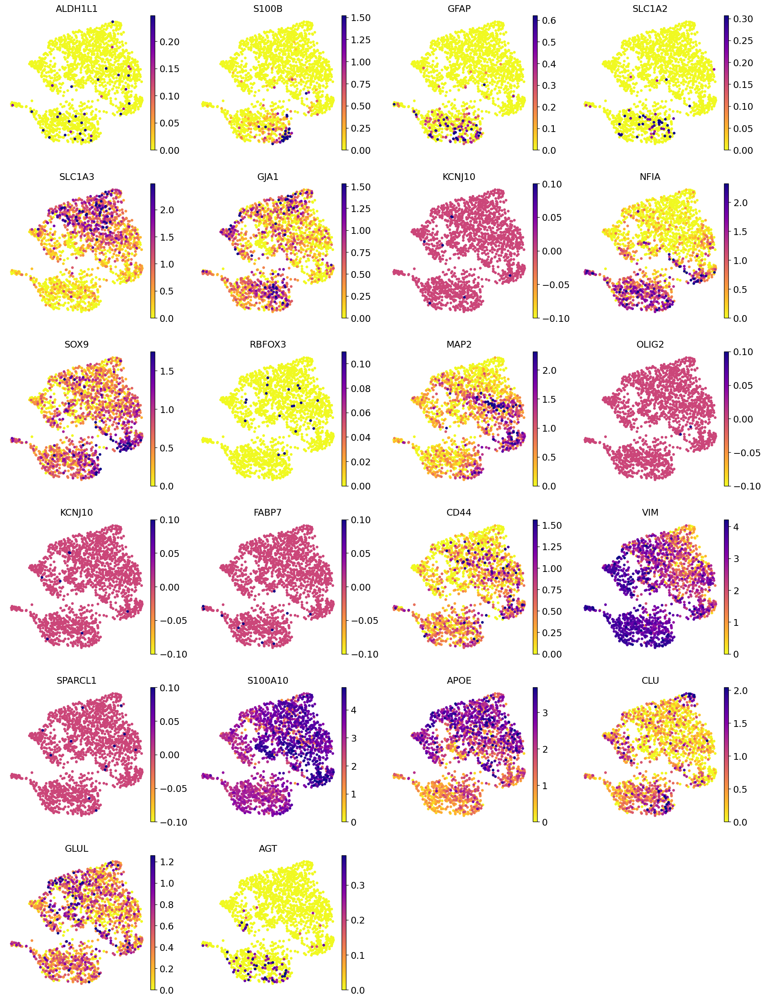

In [22]:
markers = [
    # astrocyte identity
    "ALDH1L1", "S100B", "GFAP", "AQP4",
    # functional maturity
    "SLC1A2", "SLC1A3", "GJA1", "KCNJ10",
    # program
    "NFIA", "SOX9",
    # QC (optional but good)
    "RBFOX3", "MAP2", "OLIG2",'KCNJ10',"FABP7","CD44",'VIM','SPARCL1','S100A10','APOE','CLU','GLUL','AGT',
]

sc.pl.umap(adata, color=[g for g in markers if g in adata.raw.var_names], vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,use_raw=True,
           #save='_iAstrocytes_NFIA_SOX9_differentiation.pdf'
          )

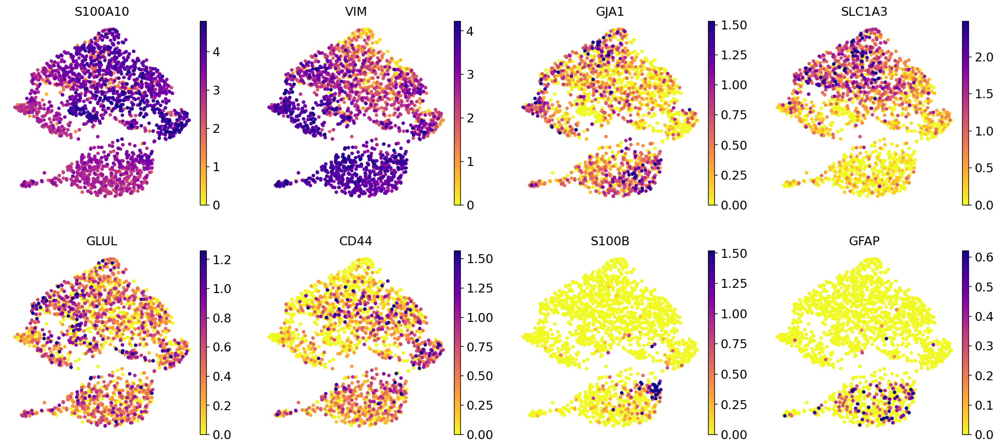

In [30]:
markers = [
    # astrocyte identity
    "ALDH1L1", "S100B", "GFAP", "AQP4",
    # functional maturity
    "SLC1A2", "SLC1A3", "GJA1", "KCNJ10",
    # program
    "NFIA", "SOX9",
    # QC (optional but good)
    "RBFOX3", "MAP2", "OLIG2",'KCNJ10',"FABP7","CD44",'VIM','SPARCL1','S100A10','APOE','CLU','GLUL','AGT',
]

markers = ['S100A10',"VIM","GJA1","SLC1A3",'GLUL','CD44',"S100B","GFAP",#"APOE",'CLU','NFIA','SOX9'
          ]
sc.pl.umap(adata, color=[g for g in markers if g in adata.raw.var_names], vmin=0, vmax='p99', cmap='plasma_r',frameon=False,ncols=4,use_raw=True,
           save='_iAstrocytes_NFIA_SOX9_differentiation.pdf'
          )